In [56]:
import csv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [57]:
def get_df(filename):
    df = pd.read_csv(
        filename,
        header=0,
        names=["threads/func", "func1", "func2", "func3"]
    )

    df = df.rename(columns={"threads/func": "threads"})

    return df

In [58]:
df_atomic = get_df("./data/measurements_atomic.csv")
df_atomic

,threads,func1,func2,func3
0,1,4972.9,1008.7,14.0
1,2,2712.8,536.7,7.1
2,4,1604.7,313.8,4.0
3,6,1267.6,263.2,4.0
4,8,1113.1,238.0,3.3
5,10,1027.9,215.7,3.0
6,12,925.0,196.2,2.8
7,16,780.2,165.5,2.6
8,20,716.5,151.3,2.7
9,100,687.0,153.0,7.4


In [59]:
df_mutex = get_df("./data/measurements_mutex.csv")
df_mutex

,threads,func1,func2,func3
0,1,4920.2,989.0,14.0
1,2,2753.9,541.6,7.1
2,4,1521.0,304.0,4.0
3,6,1268.2,260.3,3.8
4,8,1114.5,230.0,3.1
5,10,1036.0,214.7,3.1
6,12,921.0,190.5,3.1
7,16,769.0,165.5,2.8
8,20,702.8,148.8,3.0
9,100,679.9,150.0,7.3


In [60]:
percentage_diff = pd.DataFrame()
percentage_diff["threads"] = df_atomic["threads"]
for func in ["func1", "func2", "func3"]:
    percentage_diff[f"{func}_%_diff"] = (
        (df_mutex[func] - df_atomic[func]) / df_atomic[func]
    ) * 100

percentage_diff

,threads,func1_%_diff,func2_%_diff,func3_%_diff
0,1,-1.059744,-1.953009,0.000000
1,2,1.515040,0.912987,0.000000
2,4,-5.215928,-3.123008,0.000000
3,6,0.047334,-1.101824,-5.000000
4,8,0.125775,-3.361345,-6.060606
5,10,0.788014,-0.463607,3.333333
6,12,-0.432432,-2.905199,10.714286
7,16,-1.435529,0.000000,7.692308
8,20,-1.912073,-1.652346,11.111111
9,100,-1.033479,-1.960784,-1.351351


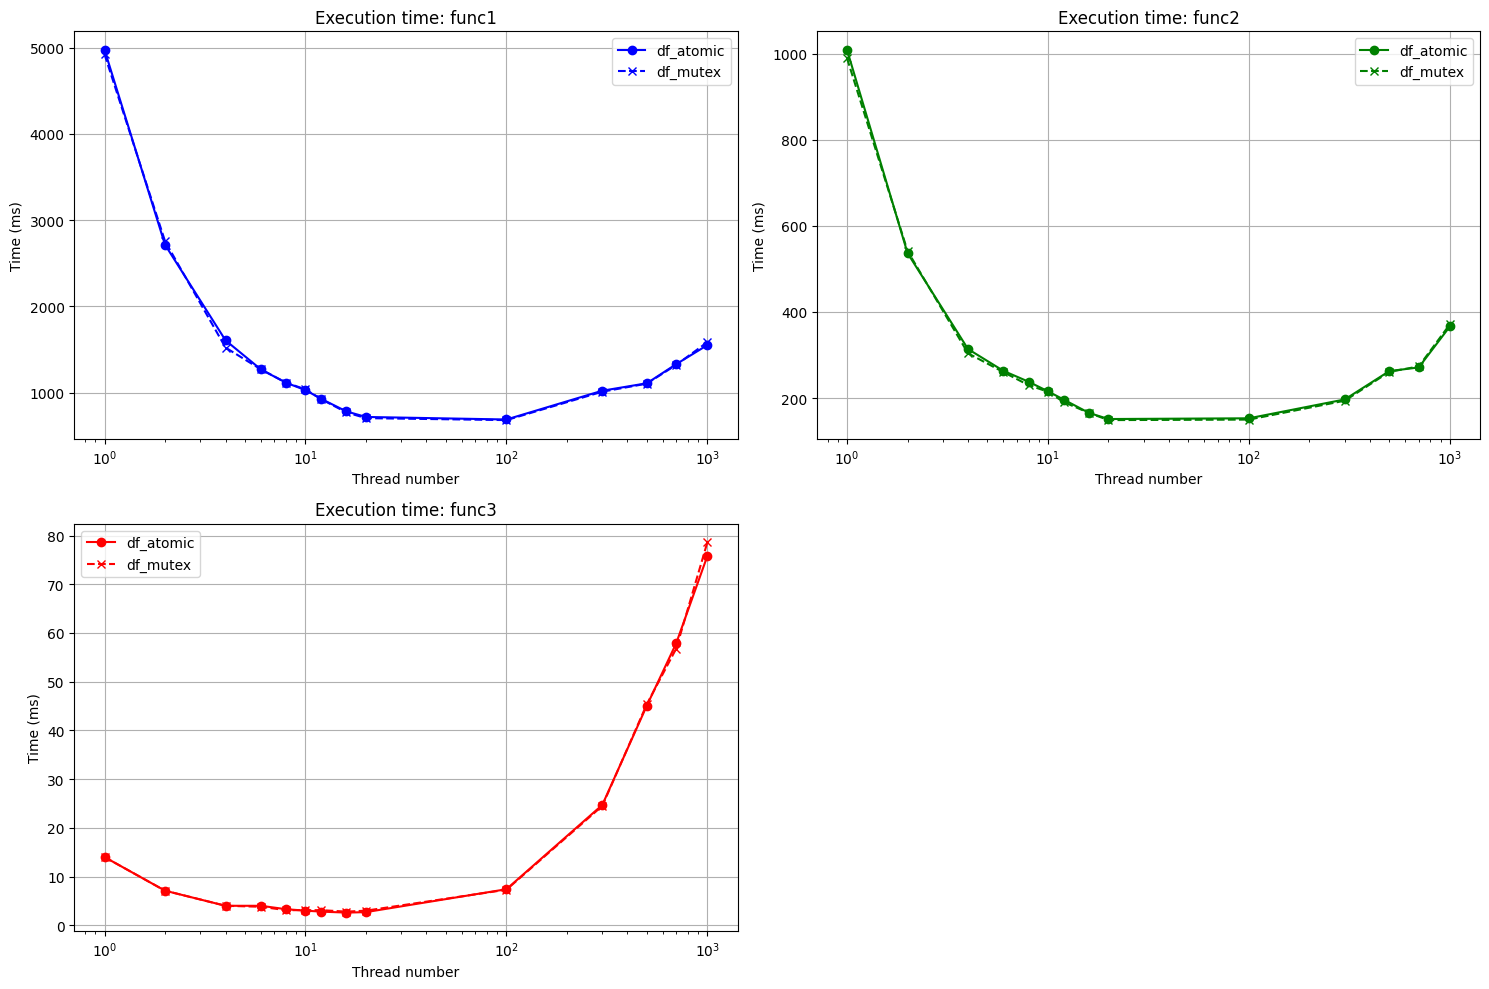

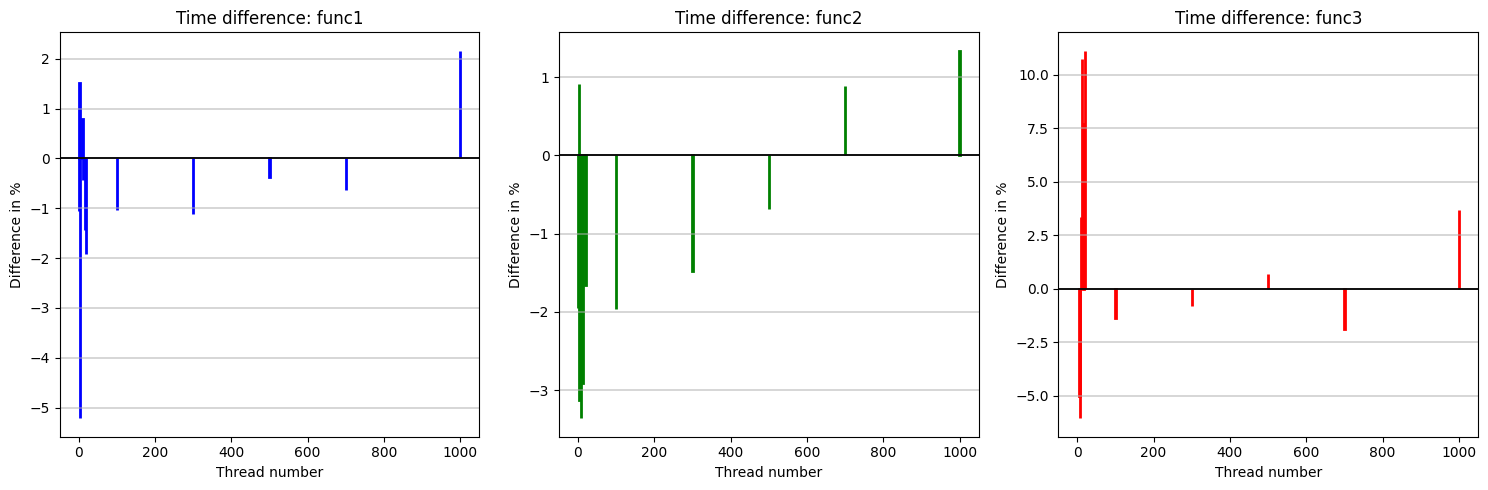

In [61]:
functions = ["func1", "func2", "func3"]
colors = ["blue", "green", "red"]

plt.figure(figsize=(15, 10))
for i, func in enumerate(functions):
    plt.subplot(2, 2, i + 1)
    plt.plot(
        df_atomic["threads"],
        df_atomic[func],
        marker="o",
        label="df_atomic",
        color=colors[i],
    )
    plt.plot(
        df_mutex["threads"],
        df_mutex[func],
        marker="x",
        label="df_mutex",
        linestyle="--",
        color=colors[i],
    )

    plt.xlabel("Thread number")
    plt.ylabel("Time (ms)")
    plt.title(f"Execution time: {func}")
    plt.xscale("log")
    plt.grid(True)
    plt.legend()

plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
for i, func in enumerate(functions):
    plt.subplot(1, 3, i + 1)

    plt.bar(
        percentage_diff["threads"],
        percentage_diff[f"{func}_%_diff"],
        color=colors[i],
        edgecolor=colors[i],
        linewidth=2,
    )
    plt.xlabel("Thread number")
    plt.ylabel("Difference in %")
    plt.title(f"Time difference: {func}")
    plt.axhline(0, color="black", linewidth=1.3)
    plt.grid(axis="y", linewidth=1.2, alpha=0.6)

plt.tight_layout()
plt.show()

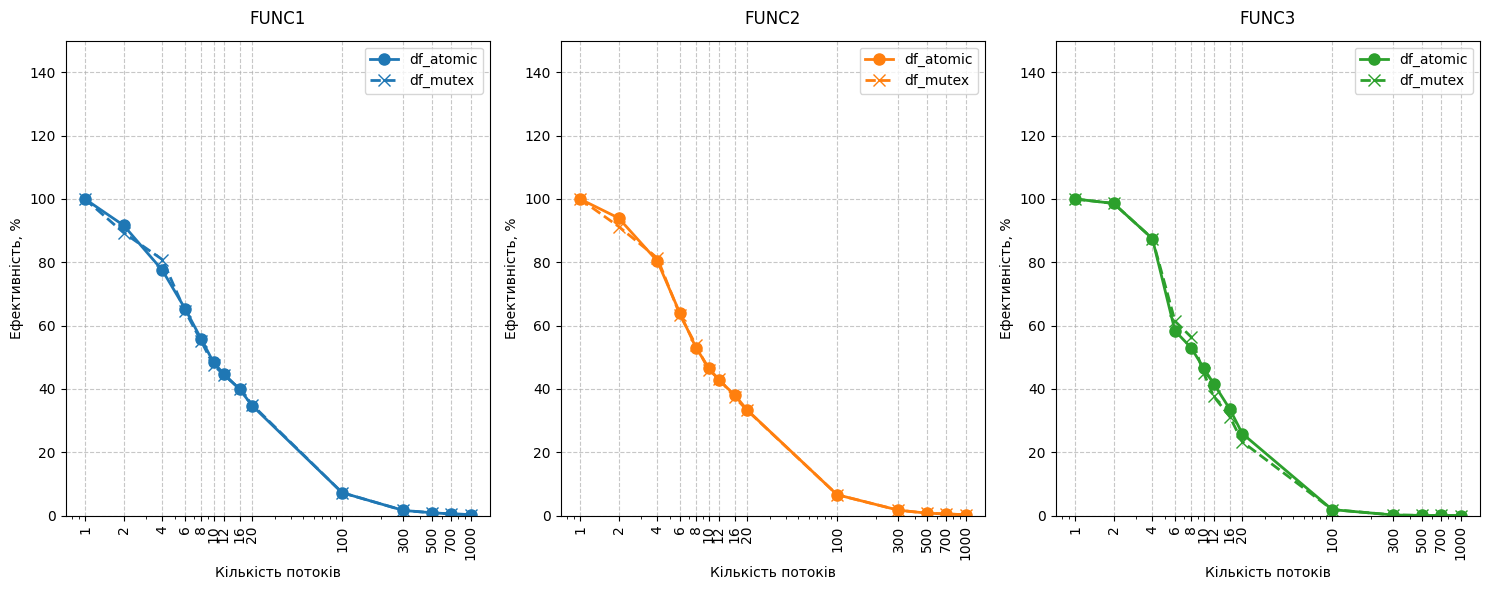

In [62]:
def calculate_efficiency(df):
    efficiency = pd.DataFrame()
    efficiency["threads"] = df["threads"]
    for func in ["func1", "func2", "func3"]:
        t1 = df[df["threads"] == 1][func].values[0]
        efficiency[f"{func}_eff"] = (t1 / df[func]) / df["threads"] * 100
    return efficiency


eff1 = calculate_efficiency(df_atomic)
eff2 = calculate_efficiency(df_mutex)


plt.figure(figsize=(15, 6))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
line_styles = ["-", "--"]
labels = ["df_atomic", "df_mutex"]

for i, func in enumerate(["func1", "func2", "func3"]):
    plt.subplot(1, 3, i + 1)

    plt.plot(
        eff1["threads"],
        eff1[f"{func}_eff"],
        marker="o",
        linestyle=line_styles[0],
        linewidth=2,
        color=colors[i],
        markersize=8,
        label=labels[0],
    )

    plt.plot(
        eff2["threads"],
        eff2[f"{func}_eff"],
        marker="x",
        linestyle=line_styles[1],
        linewidth=2,
        color=colors[i],
        markersize=8,
        label=labels[1],
    )

    plt.xscale("log")
    plt.xticks(eff1["threads"], labels=eff1["threads"], rotation=90)
    plt.xlabel("Кількість потоків", fontsize=10)
    plt.ylabel("Ефективність, %", fontsize=10)
    plt.title(f"{func.upper()}", fontsize=12, pad=12)
    plt.grid(True, linestyle="--", alpha=0.7)
    plt.ylim(0, 150)
    plt.legend()

plt.tight_layout()
plt.show()